# Saved Kelly search results

Run the cells in order to inspect the saved search results without rerunning optimization. 
Edit `params_dir` in the setup cell if the search saved to a different directory.

Use the same Optuna version as the process that saved the pickles. The current saved results 
load with the project's Optuna **4.2.1**; Optuna 5 cannot deserialize their sampler state. 
Select the matching project notebook kernel if loading reports `_ParzenEstimatorParameters` errors.


In [1]:
from pathlib import Path
import sys

# Support kernels started in either the project root or Notebooks/Search.
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "pyproject.toml").is_file() and (folder / "src" / "ufc_betting").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook from inside the SportsBetting project.")
for folder in (project_root, project_root / "src"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ufc_betting.config import settings
import importlib
import Notebooks.Search.run_search as search_helpers
importlib.reload(search_helpers)
from Notebooks.Search.run_search import run_search, plot_search_results

# Match params_dir in run_search.py. These cells load saved results; no search is run.
params_dir = settings.data_dir / "kelly_params"
search_results_dir = params_dir / "search_results"
results_by_market = {}
best_parameters_by_market = {}
search_figures = {}

def save_search_figure(fig, path):
    path = Path(path).expanduser()
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, format="png", dpi=300, bbox_inches="tight")
    return path


def save_best_parameters(frame, path):
    path = Path(path).expanduser()
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=True, index_label="parameter")
    return path


def show_saved_search(market):
    """Display saved results and return (result, best_parameters_df, figures).

    No files are saved. Pass returned objects and your exact destination paths
    to save_best_parameters(frame, path) or save_search_figure(fig, path).
    """
    save_path = search_results_dir / f"{market}_search_results.pkl"
    if not save_path.is_file():
        results_by_market.pop(market, None)
        print(f"No saved {market} search at {save_path}. Run run_search.py for this market first.")
        return None, None, {}
    result = pd.read_pickle(save_path)
    if result["odds_type"] != market:
        raise ValueError(f"{save_path} contains results for {result['odds_type']}, not {market}")
    results_by_market[market] = result
    print(f"Loaded {save_path}")
    print(f"Best trial: {result['best_trial_number'] + 1} (displayed one-based)")
    print(f"Best objective: {result['best_value']:.6g}")
    best_parameters = pd.Series(result["best_params"], name="Best parameters").to_frame()
    best_parameters_by_market[market] = best_parameters
    display(best_parameters)
    summary = result["objective_breakdown"].assign(
        odds_type=market,
        best_trial_number=result["best_trial_number"],  # Saved Optuna number is zero-based.
        use_decay=result["use_decay"],
    )
    display(summary.round(3))
    if "path_selection" in result:
        display(pd.Series(result["path_selection"], name="Saved path selection").to_frame())
    if "sampled_path_results" in result:
        display(result["sampled_path_results"][["terminal_return", "ending_bankroll"]].describe())
    figures = plot_search_results(result, show=False)[market]
    search_figures[market] = figures
    for name, fig in figures.items():
        display(fig)
        plt.close(fig)
    return result, best_parameters, figures


c:\Users\jcmar\my_files\SportsBetting\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded C:\Users\jcmar\my_files\SportsBetting\Data\kelly_params\search_results\open_search_results.pkl
Best trial: 253 (displayed one-based)
Best objective: 0.015534


,Best parameters
mdd,0.37
N,1203.00
mdd_parlay,0.23
N_parlay,381.00
z,0.36
moneyline_min_american,-550.00


,mean_terminal_return_pct,std_terminal_return_pct,risk_penalty,score_type,objective_score,wealth_floor,floored_path_fraction,loss_probability,mean_event_log_growth,mean_max_drawdown,...,drawdown_penalty_amount,mean_ulcer_index,ulcer_penalty_amount,ulcer_penalty,drawdown_penalty,drawdown_tail_fraction,geometric_growth_per_event_pct,odds_type,best_trial_number,use_decay
0,311001.872,1756832.018,0.15,event_log_growth,0.016,0.001,0.001,0.007,0.078,0.697,...,0.057,0.3,0.006,0.02,0.067,0.33,8.133,open,252,False


,Saved path selection
paths_path,C:\Users\jcmar\my_files\SportsBetting\Data\boo...
n_paths,3000
seed,42
sample_prices,False
prediction_model_type,open


,terminal_return,ending_bankroll
count,3000.000000,3.000000e+03
mean,3110.018724,1.555509e+06
std,17568.320179,8.784160e+06
min,-1.000000,0.000000e+00
25%,55.348690,2.817434e+04
50%,293.335110,1.471676e+05
75%,1277.470092,6.392350e+05
max,663277.802705,3.316394e+08


c:\Users\jcmar\my_files\SportsBetting\Notebooks\Search\run_search.py:178: ExperimentalWarning: plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  axes = plotter(
c:\Users\jcmar\my_files\SportsBetting\Notebooks\Search\run_search.py:178: ExperimentalWarning: plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  axes = plotter(


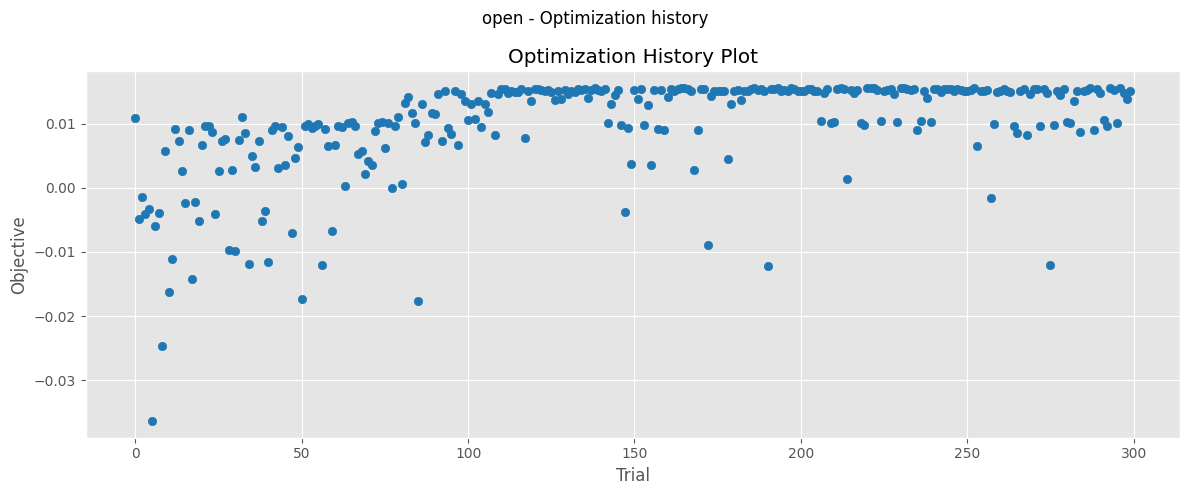

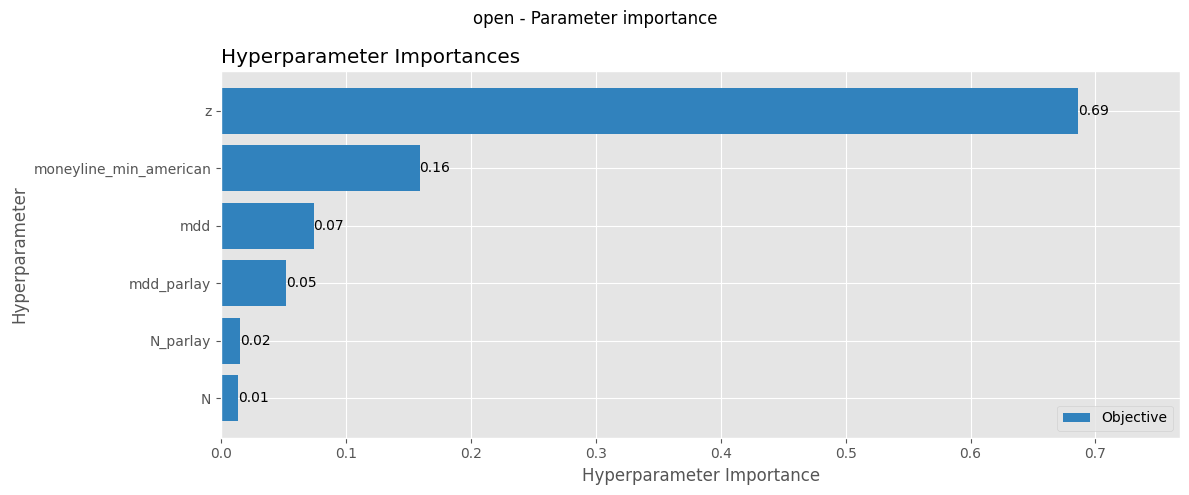

WindowsPath('C:/Users/jcmar/my_files/SportsBetting/Data/kelly_params/search_results/open_parameter_importance.png')

In [2]:
open_results, open_best_parameters, open_figures = show_saved_search("open")
open_best_parameters.to_csv(search_results_dir / "open_best_parameters.csv", index=True, index_label="parameter")
save_search_figure(
    open_figures["optimization_history"],
    search_results_dir / "open_optimization_history.png",
)
save_search_figure(
    open_figures["parameter_importance"],
    search_results_dir / "open_parameter_importance.png",
)

Loaded C:\Users\jcmar\my_files\SportsBetting\Data\kelly_params\search_results\close1_search_results.pkl
Best trial: 286 (displayed one-based)
Best objective: 0.000824502


,Best parameters
z,1.54
N,11
N_parlay,782
mdd,0.31
mdd_parlay,0.05
moneyline_max_american,None
decay_rates,"{'k_down': 49.92299769785077, 'k_up': 2.477040..."
opening_params,"{'z': 0.36000000000000004, 'N': 1203, 'N_parla..."
moneyline_min_american,-225.0


,mean_terminal_return_pct,std_terminal_return_pct,risk_penalty,score_type,objective_score,wealth_floor,floored_path_fraction,loss_probability,mean_event_log_growth,mean_max_drawdown,...,drawdown_penalty_amount,mean_ulcer_index,ulcer_penalty_amount,ulcer_penalty,drawdown_penalty,drawdown_tail_fraction,geometric_growth_per_event_pct,odds_type,best_trial_number,use_decay
0,2399.413,3001.771,0.25,event_log_growth,0.001,0.001,0.0,0.004,0.038,0.381,...,0.035,0.14,0.003,0.02,0.067,0.33,3.899,close1,285,True


,Saved path selection
paths_path,C:\Users\jcmar\my_files\SportsBetting\Data\boo...
n_paths,3000
seed,42
sample_prices,False
prediction_model_type,open


,terminal_return,ending_bankroll
count,3000.000000,3000.000000
mean,23.994128,12497.064164
std,30.017708,15008.854076
min,-0.784161,107.919442
25%,7.256542,4128.271228
50%,15.388729,8194.364470
75%,29.299703,15149.851709
max,432.368033,216684.016393


c:\Users\jcmar\my_files\SportsBetting\Notebooks\Search\run_search.py:178: ExperimentalWarning: plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  axes = plotter(
c:\Users\jcmar\my_files\SportsBetting\Notebooks\Search\run_search.py:178: ExperimentalWarning: plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  axes = plotter(


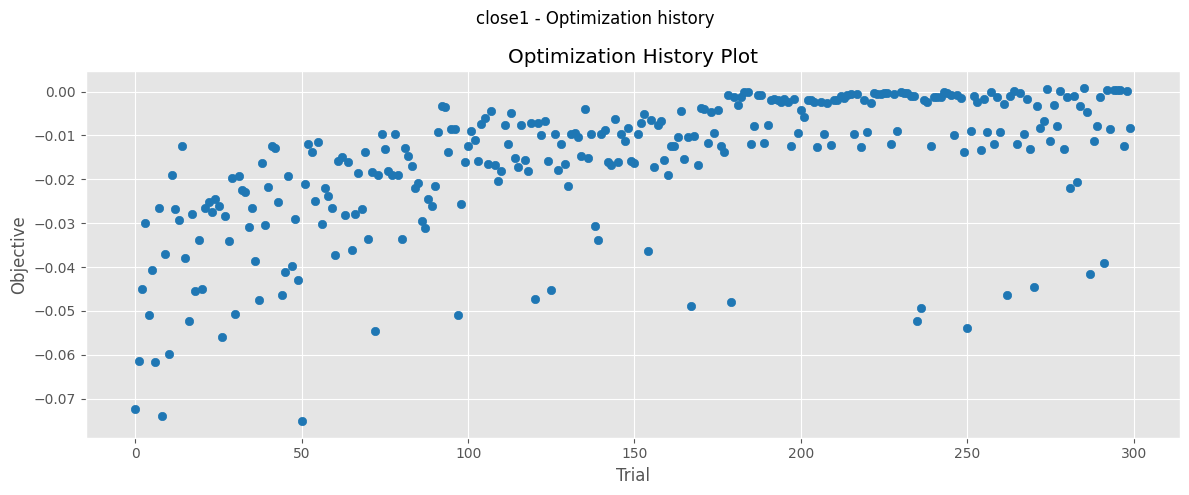

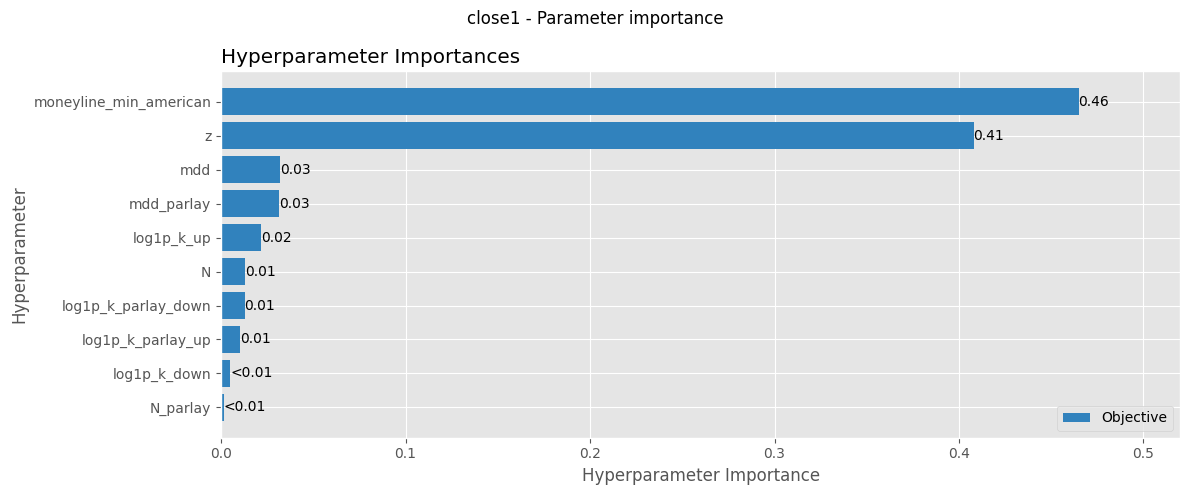

WindowsPath('C:/Users/jcmar/my_files/SportsBetting/Data/kelly_params/search_results/close1_parameter_importance.png')

In [3]:
close1_results, close1_best_parameters, close1_figures = show_saved_search("close1")
close1_best_parameters.to_csv(search_results_dir / "close1_best_parameters.csv", index=True, index_label="parameter")

save_search_figure(
    close1_figures["optimization_history"],
    search_results_dir / "close1_optimization_history.png",
)
save_search_figure(
    close1_figures["parameter_importance"],
    search_results_dir / "close1_parameter_importance.png",
)

Loaded C:\Users\jcmar\my_files\SportsBetting\Data\kelly_params\search_results\close2_search_results.pkl
Best trial: 270 (displayed one-based)
Best objective: 0.0091676


,Best parameters
z,1.1
N,218
N_parlay,68
mdd,0.57
mdd_parlay,0.03
moneyline_max_american,None
decay_rates,"{'k_down': 23.73724679964053, 'k_up': 0.305131..."
opening_params,"{'z': 0.36000000000000004, 'N': 1203, 'N_parla..."
moneyline_min_american,-200.0


,mean_terminal_return_pct,std_terminal_return_pct,risk_penalty,score_type,objective_score,wealth_floor,floored_path_fraction,loss_probability,mean_event_log_growth,mean_max_drawdown,...,drawdown_penalty_amount,mean_ulcer_index,ulcer_penalty_amount,ulcer_penalty,drawdown_penalty,drawdown_tail_fraction,geometric_growth_per_event_pct,odds_type,best_trial_number,use_decay
0,27728.263,93984.913,0.25,event_log_growth,0.009,0.001,0.0,0.005,0.061,0.548,...,0.047,0.216,0.004,0.02,0.067,0.33,6.243,close2,269,True


,Saved path selection
paths_path,C:\Users\jcmar\my_files\SportsBetting\Data\boo...
n_paths,3000
seed,42
sample_prices,False
prediction_model_type,open


,terminal_return,ending_bankroll
count,3000.000000,3.000000e+03
mean,277.282635,1.391413e+05
std,939.849129,4.699246e+05
min,-0.915424,4.228816e+01
25%,26.379972,1.368999e+04
50%,80.940184,4.097009e+04
75%,231.050045,1.160250e+05
max,29183.682364,1.459234e+07


c:\Users\jcmar\my_files\SportsBetting\Notebooks\Search\run_search.py:178: ExperimentalWarning: plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  axes = plotter(
c:\Users\jcmar\my_files\SportsBetting\Notebooks\Search\run_search.py:178: ExperimentalWarning: plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  axes = plotter(


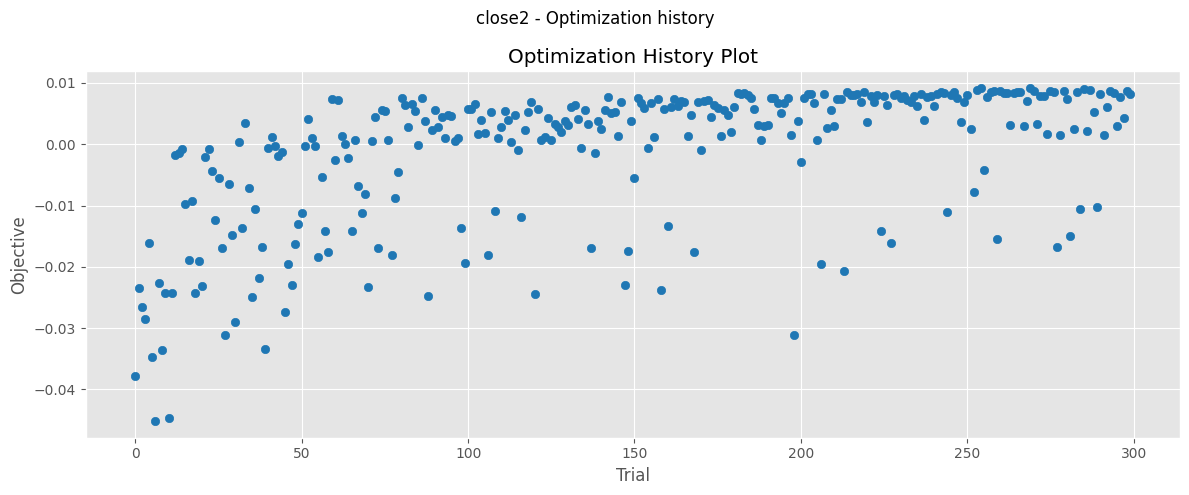

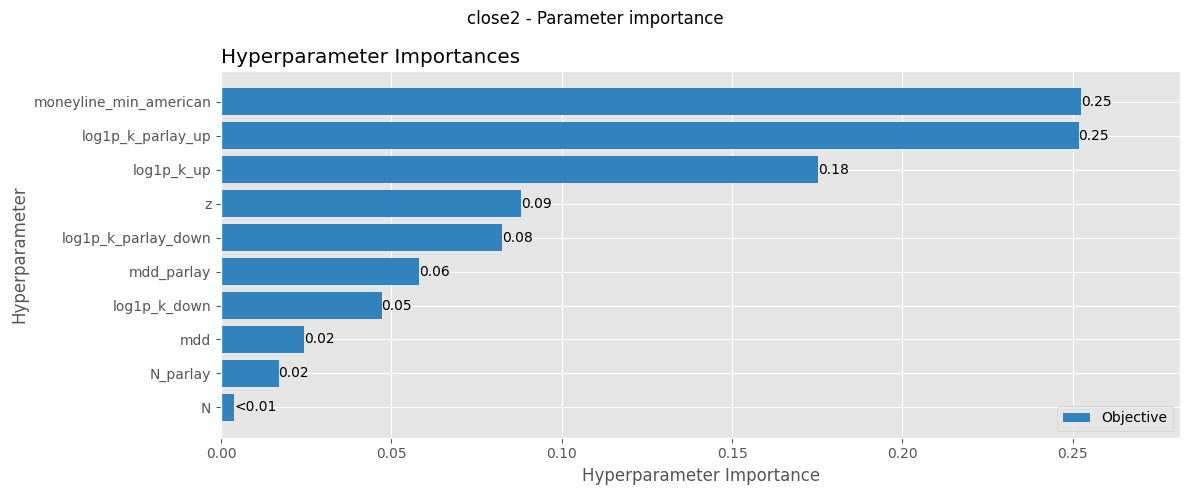

WindowsPath('C:/Users/jcmar/my_files/SportsBetting/Data/kelly_params/search_results/close2_parameter_importance.png')

In [4]:
close2_results, close2_best_parameters, close2_figures = show_saved_search("close2")
close2_best_parameters.to_csv(search_results_dir / "close2_best_parameters.csv", index=True, index_label="parameter")
save_search_figure(
    close2_figures["optimization_history"],
    search_results_dir / "close2_optimization_history.png",
)
save_search_figure(
    close2_figures["parameter_importance"],
    search_results_dir / "close2_parameter_importance.png",
)

### Fitted decay through the validation data

The moneyline curve is the opening-policy weight $w=\exp(-k_{direction}|\log(C/O)|)$; the closing-policy weight is $1-w$. Dots show the predicted side of each validation fight, including fights that may receive zero stake.

Parlays use the two highest-EV predicted sides per event. Their weight is $\exp(-k_{parlay,down}D-k_{parlay,up}U)$, where $D$ and $U$ sum the negative and positive log movements separately across the legs. Opposing movements do not cancel. The surface shows this function and dots locate the observed candidate tickets. These are allocation weights **before z correction and the exposure cap**, not predicted returns.

These plots use the parameters and reference validation predictions from the same saved search result. They describe the reference dataset, not the synthetic path cards or sampled intermediate prices. Missing results or searches without fitted decay are skipped. No search is rerun.


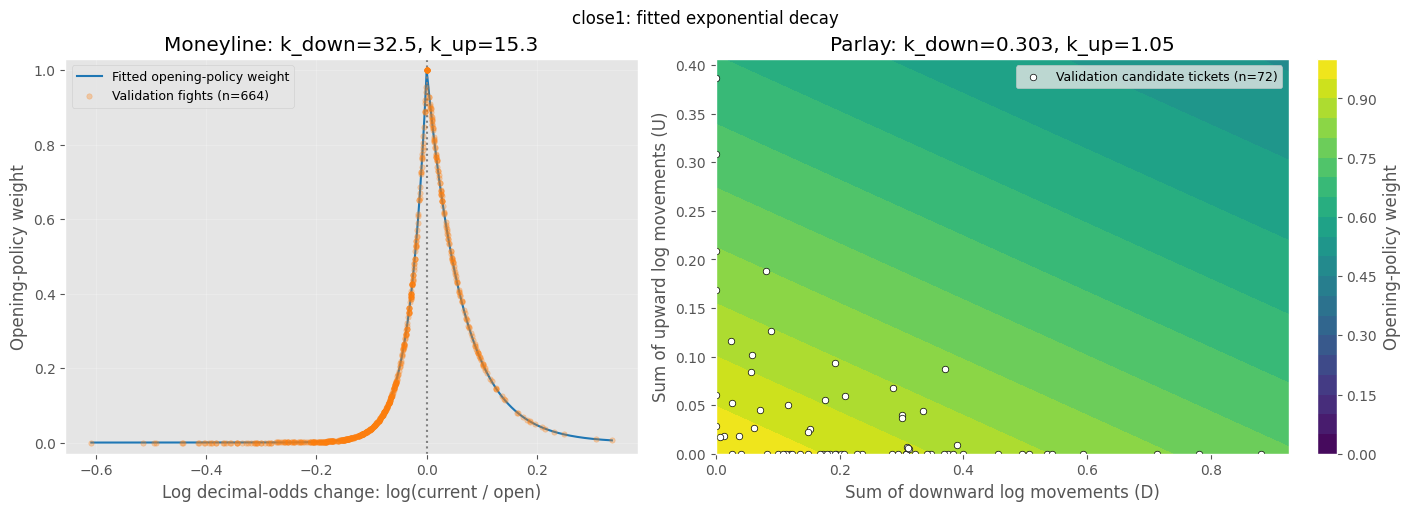

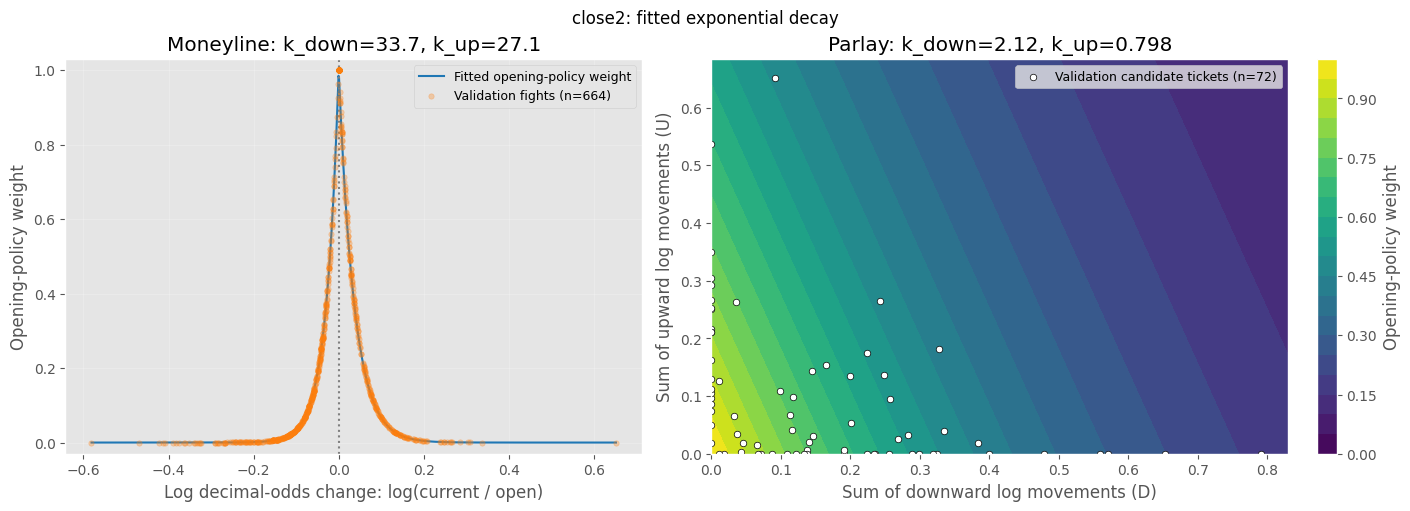

: 

In [ ]:
import numpy as np
from ufc_betting.BettingStrategy.betting_params import BettingParams
from ufc_betting.BettingStrategy.betting_returns import BettingReturnCalculator


def plot_fitted_decay(data, params, odds_type):
    """Plot fitted opening-policy weights over observed fight/ticket movements."""
    rates = BettingParams.from_value(params).decay_rates
    if rates is None:
        raise ValueError(f"{odds_type}: no fitted decay rates")
    frame = data.copy().reset_index(drop=True)
    frame["date"] = pd.to_datetime(frame["date"]).dt.normalize()
    side = (frame["proba_red"].to_numpy() >= 0.5).astype(int)
    rows = np.arange(len(frame))
    opening = frame[["dec_open_blue", "dec_open_red"]].to_numpy(float)[rows, side]
    current = frame[[f"dec_{odds_type}_blue", f"dec_{odds_type}_red"]].to_numpy(float)[rows, side]
    weights = BettingReturnCalculator.decay_weights(
        opening, current, rates["k_down"], rates["k_up"])
    movement = np.log(current / opening)
    has_parlay = {"k_parlay_down", "k_parlay_up"} <= rates.keys()
    fig, axes = plt.subplots(1, 2 if has_parlay else 1,
                             figsize=(14 if has_parlay else 7, 5), squeeze=False,
                             layout="constrained")
    ax = axes[0, 0]
    grid = np.linspace(min(movement.min(), -0.01), max(movement.max(), 0.01), 1001)
    curve = np.exp(-np.where(grid < 0, rates["k_down"], rates["k_up"]) * np.abs(grid))
    ax.plot(grid, curve, color="tab:blue", label="Fitted opening-policy weight")
    ax.scatter(movement, weights, s=15, alpha=0.3, color="tab:orange",
               label=f"Validation fights (n={len(frame)})", zorder=3)
    ax.axvline(0, color="gray", linestyle=":")
    ax.set(title=f"Moneyline: k_down={rates['k_down']:.3g}, k_up={rates['k_up']:.3g}",
           xlabel="Log decimal-odds change: log(current / open)",
           ylabel="Opening-policy weight", ylim=(-0.03, 1.03))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)

    if has_parlay:
        probability = np.where(side == 1, frame.proba_red, 1 - frame.proba_red)
        ev = probability * current - 1
        tickets = []
        for ids in frame.groupby("date", sort=True).indices.values():
            if len(ids) < 2:
                continue
            legs = ids[np.argsort(-ev[ids], kind="stable")[:2]]
            moves = movement[legs]
            tickets.append((np.maximum(-moves, 0).sum(), np.maximum(moves, 0).sum()))
        observed = np.asarray(tickets).reshape(-1, 2)
        limits = np.maximum(observed.max(axis=0) * 1.05, 0.01) if len(observed) else [0.1, 0.1]
        down, up = np.meshgrid(np.linspace(0, limits[0], 150), np.linspace(0, limits[1], 150))
        surface = np.exp(-rates["k_parlay_down"] * down - rates["k_parlay_up"] * up)
        ax = axes[0, 1]
        contour = ax.contourf(down, up, surface, levels=np.linspace(0, 1, 21), cmap="viridis")
        fig.colorbar(contour, ax=ax, label="Opening-policy weight")
        if len(observed):
            ax.scatter(observed[:, 0], observed[:, 1], s=22, color="white", edgecolors="black",
                       linewidths=0.5, label=f"Validation candidate tickets (n={len(observed)})")
            ax.legend(fontsize=9)
        ax.set(title=f"Parlay: k_down={rates['k_parlay_down']:.3g}, k_up={rates['k_parlay_up']:.3g}",
               xlabel="Sum of downward log movements (D)", ylabel="Sum of upward log movements (U)")
    fig.suptitle(f"{odds_type}: fitted exponential decay")
    return fig, axes


decay_figures = {}
for market in ("close1", "close2"):
    fitted = results_by_market.get(market)
    if fitted is None:
        print(f"Skipping {market} decay plot: load its saved search results above first.")
        continue
    params = fitted["betting_params"]
    if BettingParams.from_value(params).decay_rates is None:
        print(f"Skipping {market}: this search did not fit decay rates.")
        continue
    data = fitted["validation_predictions"]
    fig, axes = plot_fitted_decay(data, params, market)
    decay_figures[market] = fig
    search_figures.setdefault(market, {})["fitted_decay"] = fig
    display(fig)
    plt.close(fig)


In [ ]:
# Saving is optional: supply your own full destination paths.
# save_best_parameters(open_best_parameters, r"C:/your/folder/open_parameters.csv")
# save_search_figure(open_figures["optimization_history"], r"C:/your/folder/open_history.png")
# save_search_figure(open_figures["parameter_importance"], r"C:/your/folder/open_importance.png")
# save_search_figure(decay_figures["close1"], r"C:/your/folder/close1_decay.png")
